# Temporal persistence — retention curves (figure & table)

Pooled recompute from the per-condition cache `results/temporal_persistence/<model>/cond_*.pt` (robust to which datatype process wrote summary.json). cos(pivot goal-encoding, encoding at x% of the implementation) over relation masks. **teal = same sub-goal (signal); orange = different sub-goal (baseline); dashed = cross-language.** Saves to `notebooks/Figures/temporal_persistence/`.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
import glob, torch
import numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
from src.goals import temporal_persistence as TP
from rich import print as rich_print
from rich.table import Table
GROUP='temporal_persistence'; SLUG='Qwen2.5-Coder-32B-Instruct'
cdir=TP.cache_dir(SLUG)
recs=[torch.load(p)['record'] for p in glob.glob(os.path.join(cdir,'cond_*.pt'))]
from collections import Counter
per_cell=dict(Counter(f"{r['datatype']}/{r['lang']}" for r in recs))
grid=TP.DEFAULT_PROG_GRID
curves=TP.compute_curves(recs, grid, collapse_lang=True)  # ii+ii*, iv+iv* pooled
print(f'{len(recs)} conditions | per-cell {per_cell}')

3088 conditions | per-cell {'list[str]/cpp': 504, 'int/cpp': 502, 'str/python': 225, 'list[int]/python': 238, 'list[int]/cpp': 488, 'str/cpp': 472, 'list[str]/python': 371, 'int/python': 288}


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/temporal_persistence/retention_curves_sem.pdf


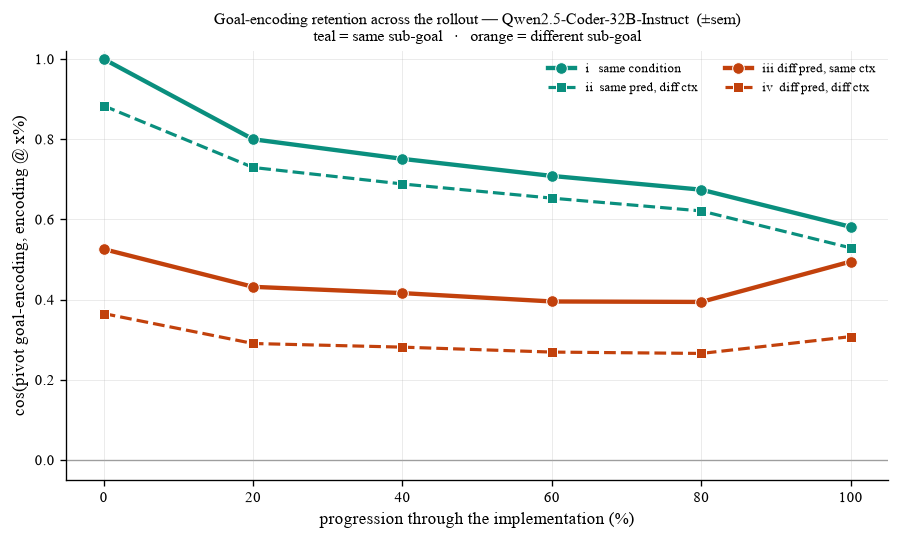

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/temporal_persistence/retention_curves_std.pdf


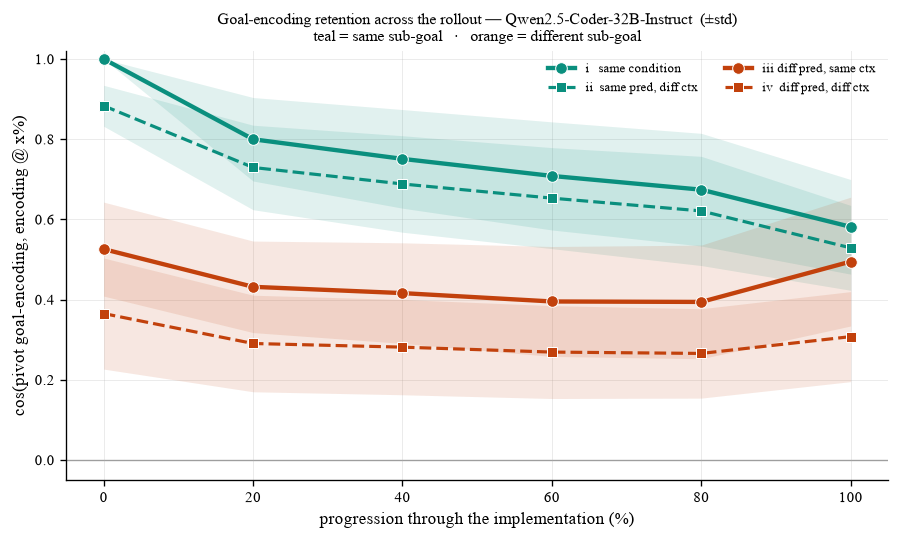

In [2]:
# 4-mask retention (cross-lang collapsed): teal=same sub-goal, orange=different sub-goal.
T,O=F.TP_TEAL,F.TP_ORANGE
STYLE={
 'i   same condition':      (T,'-','o',2.6,7),
 'ii  same pred, diff ctx': (T,'--','s',1.9,6),
 'iii diff pred, same ctx': (O,'-','o',2.6,7),
 'iv  diff pred, diff ctx': (O,'--','s',1.9,6)}
for err in ['sem','std']:
    fig,ax=plt.subplots(figsize=(7.6,4.6)); xs=[p*100 for p in grid]
    for name,cur in curves.items():
        color,ls,mk,lw,ms=STYLE.get(name,('grey','-','o',1.5,5))
        mu=np.array([cur[p]['mean'] for p in grid]); er=np.array([cur[p][err] for p in grid])
        ax.plot(xs,mu,ls=ls,marker=mk,color=color,lw=lw,markersize=ms,
                markeredgecolor='white',markeredgewidth=0.6,label=name,zorder=3)
        ax.fill_between(xs,mu-er,mu+er,color=color,alpha=0.12,lw=0,zorder=1)
    ax.axhline(0,color='#999',lw=.8,zorder=0)
    ax.set_xlabel('progression through the implementation (%)')
    ax.set_ylabel('cos(pivot goal-encoding, encoding @ x%)'); ax.set_ylim(top=1.02)
    ax.set_title(f'Goal-encoding retention across the rollout — {SLUG}  (\u00b1{err})\n'
                 f'teal = same sub-goal   \u00b7   orange = different sub-goal',fontsize=9.5)
    ax.legend(fontsize=8,ncol=2,frameon=False,loc='upper right')
    fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,f'retention_curves_{err}')); plt.show()

                     Retention cos(pivot, enc @ x%) — 3088 conditions                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┓
┃ comparison              ┃       n ┃     0% ┃    20% ┃    40% ┃    60% ┃    80% ┃   100% ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━┩
│ i   same condition      │    3088 │ +1.000 │ +0.800 │ +0.751 │ +0.708 │ +0.674 │ +0.581 │
│ ii  same pred, diff ctx │  161460 │ +0.883 │ +0.729 │ +0.688 │ +0.653 │ +0.621 │ +0.529 │
│ iii diff pred, same ctx │    3846 │ +0.526 │ +0.432 │ +0.416 │ +0.395 │ +0.394 │ +0.495 │
│ iv  diff pred, diff ctx │ 9367350 │ +0.365 │ +0.290 │ +0.281 │ +0.269 │ +0.266 │ +0.308 │
└─────────────────────────┴─────────┴────────┴────────┴────────┴────────┴────────┴────────┘

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/temporal_persistence/retention_table.tex


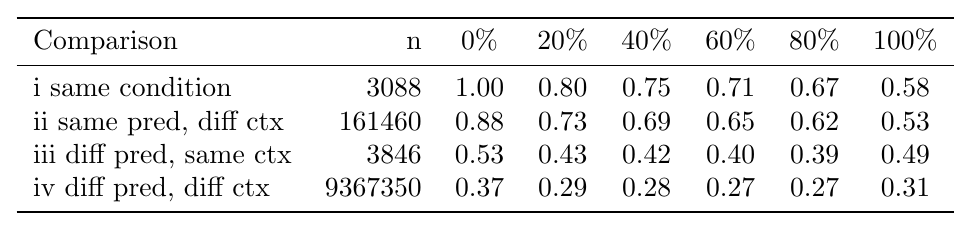

In [3]:
# table of the pooled curves + .tex
t=Table(title=f'Retention cos(pivot, enc @ x%) — {len(recs)} conditions')
t.add_column('comparison'); t.add_column('n',justify='right')
[t.add_column(f'{int(p*100)}%',justify='right') for p in grid]
for name,cur in curves.items():
    t.add_row(name, str(cur[grid[0]]['n']), *[f"{cur[p]['mean']:+.3f}" for p in grid])
rich_print(t)
hdr=' & '.join(['Comparison','n']+[f'{int(p*100)}\\%' for p in grid])
body=' \\\\\n'.join(name.replace('*','$^*$')+f" & {cur[grid[0]]['n']} & "+' & '.join(f"{cur[p]['mean']:.2f}" for p in grid) for name,cur in curves.items())
tex='\\begin{tabular}{lr'+'c'*len(grid)+'}\n\\toprule\n'+hdr+' \\\\\n\\midrule\n'+body+' \\\\\n\\bottomrule\n\\end{tabular}'
print('wrote',F.save_table(tex,GROUP,'retention_table'))
img=F.render_latex_table(tex); img if img is not None else rich_print('[dim](latex preview unavailable)[/dim]')

In [ ]:
# goal vs control retention (Figure 30, fig:retention-control): impl spans 10-40 tokens, goal records matched
# to the control conditions; finer early grid (5/10/15%) to show where the control encoding collapses.
SPAN = (10, 40)
GRID_GC = [0.0, 0.05, 0.10, 0.15, 0.2, 0.4, 0.6, 0.8, 1.0]
_ctrl = [torch.load(p)['record'] for p in glob.glob(os.path.join(cdir, 'control', 'cond_*.pt'))]
_key = lambda r: (r['datatype'], r['lang'], r['pred_id'], r['ctx_key'], r['pos'])
_ck = {_key(r) for r in _ctrl}
_inspan = lambda R: [r for r in R if SPAN[0] <= r['n_impl'] <= SPAN[1]]
goal_m, ctrl_m = _inspan([r for r in recs if _key(r) in _ck]), _inspan(_ctrl)
panels = [(f'GOAL heads (122)  n={len(goal_m)} matched', TP.compute_curves(goal_m, GRID_GC, collapse_lang=True)),
          (f'CONTROL heads (122, later-half non-goal)  n={len(ctrl_m)}', TP.compute_curves(ctrl_m, GRID_GC, collapse_lang=True))]
err = 'std'
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.7), sharey=True)
xs = [p * 100 for p in GRID_GC]
for ax, (title, cur_set) in zip(axes, panels):
    for name, cur in cur_set.items():
        color, ls, mk, lw, ms = STYLE.get(name, ('grey', '-', 'o', 1.5, 5))
        mu = np.array([cur[p]['mean'] for p in GRID_GC]); er = np.array([cur[p][err] for p in GRID_GC])
        ax.plot(xs, mu, ls=ls, marker=mk, color=color, lw=lw, markersize=ms,
                markeredgecolor='white', markeredgewidth=0.6, label=name, zorder=3)
        ax.fill_between(xs, mu - er, mu + er, color=color, alpha=0.12, lw=0, zorder=1)
    ax.axhline(0, color='#999', lw=.8, zorder=0); ax.set_ylim(top=1.02)
    ax.set_xticks([0, 5, 10, 15, 20, 40, 60, 80, 100])
    ax.set_xlabel('progression through the implementation (%)')
    ax.set_title(f'{title}\nteal = same sub-goal  ·  orange = different sub-goal', fontsize=9.5)
    ax.legend(fontsize=7.5, ncol=2, frameon=False, loc='upper right')
axes[0].set_ylabel('cos(pivot goal-encoding, encoding @ x%)')
fig.suptitle(f'Temporal persistence — goal vs control  (impl spans {SPAN[0]}-{SPAN[1]} tokens, {SLUG}, ±{err})', fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.95))
print('saved', F.save_fig(fig, GROUP, f'goal_vs_control_{err}_impl{SPAN[0]}-{SPAN[1]}')); plt.show()
t = Table(title=f'cos(pivot, enc @ x%) — impl {SPAN[0]}-{SPAN[1]} tokens')
t.add_column('heads'); t.add_column('comparison'); [t.add_column(f'{p*100:g}%', justify='right') for p in GRID_GC]
for (title, cur_set) in panels:
    for name, cur in cur_set.items():
        t.add_row(title.split()[0], name, *[f"{cur[p]['mean']:.3f}" for p in GRID_GC])
rich_print(t)


In [ ]:
# Goal-head retention (main-text fig:temporal-retention, retention_curves_std): impl spans 10-40 tokens, ALL goal
# conditions (not only those matched to the control set), with the finer early grid 0/5/10/15/20/40/60/80/100%.
SPAN_R = (10, 40)
GRID_FINE = [0.0, 0.05, 0.10, 0.15, 0.2, 0.4, 0.6, 0.8, 1.0]
recs_span = [r for r in recs if SPAN_R[0] <= r['n_impl'] <= SPAN_R[1]]
curves_span = TP.compute_curves(recs_span, GRID_FINE, collapse_lang=True)
err = 'std'
fig, ax = plt.subplots(figsize=(7.6, 4.6)); xs = [p * 100 for p in GRID_FINE]
for name, cur in curves_span.items():
    color, ls, mk, lw, ms = STYLE.get(name, ('grey', '-', 'o', 1.5, 5))
    mu = np.array([cur[p]['mean'] for p in GRID_FINE]); er = np.array([cur[p][err] for p in GRID_FINE])
    ax.plot(xs, mu, ls=ls, marker=mk, color=color, lw=lw, markersize=ms,
            markeredgecolor='white', markeredgewidth=0.6, label=name, zorder=3)
    ax.fill_between(xs, mu - er, mu + er, color=color, alpha=0.12, lw=0, zorder=1)
ax.axhline(0, color='#999', lw=.8, zorder=0)
ax.set_xticks([0, 5, 10, 15, 20, 40, 60, 80, 100])
ax.set_xlabel('progression through the implementation (%)')
ax.set_ylabel('cos(pivot goal-encoding, encoding @ x%)'); ax.set_ylim(top=1.02)
ax.set_title(f'Goal-encoding retention across the rollout — {SLUG}  (±{err})\n'
             f'impl spans {SPAN_R[0]}-{SPAN_R[1]} tokens · teal = same sub-goal · orange = different sub-goal', fontsize=9.5)
ax.legend(fontsize=8, ncol=2, frameon=False, loc='upper right')
fig.tight_layout(); print(f'{len(recs_span)} conditions · saved', F.save_fig(fig, GROUP, f'retention_curves_{err}')); plt.show()
for name, cur in curves_span.items():
    print(f"{name:<26}" + "".join(f"  {int(p*100):>3}%={cur[p]['mean']:.3f}" for p in GRID_FINE))